# Prática 2 — Leitura de Hidrômetros com CNNs

Classificação de dígitos do dataset **Yandex.Toloka WaterMeters** com `smallcnn`, AlexNet, VGG16 e ResNet18.

> Licença do dataset: CC BY-NC-ND 4.0. Limpar as saídas que exibem imagens do dataset antes do commit.

## Ambiente

Os resultados entregues foram obtidos no **Google Colab (GPU T4)**. Para reproduzir:

1. *Ambiente de execução → Alterar o tipo de ambiente → T4 GPU*.
2. Em *Secrets* (ícone de chave na barra lateral), criar `KAGGLE_API_TOKEN` com o token da API do Kaggle e liberar o acesso ao notebook.
3. Executar todas as células; a próxima pede o upload do `splits.csv` oficial.

Localmente, basta ter o token em `~/.kaggle/access_token` e o `splits.csv` na pasta do notebook.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=True)
    from google.colab import files, userdata

    if not Path("splits.csv").exists():
        print("Envie o splits.csv oficial:")
        files.upload()
    if "KAGGLE_API_TOKEN" not in os.environ:
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            from getpass import getpass
            os.environ["KAGGLE_API_TOKEN"] = getpass("Token da API do Kaggle: ")

assert Path("splits.csv").exists(), "splits.csv oficial não encontrado na pasta do notebook"
print("Colab:", IN_COLAB, "| pasta:", Path.cwd())

Envie o splits.csv oficial:


Saving splits.csv to splits.csv
Colab: True | pasta: /content


## Configuração

In [2]:
import ast
import hashlib
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd()
DATA = ROOT / "data"
IMG_DIR = DATA / "images"
MASK_DIR = DATA / "masks"
COLLAGE_DIR = DATA / "collage"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)


def imread(path, flags=cv2.IMREAD_COLOR):
    """cv2.imread falha com caminhos com acento no Windows; lê via numpy."""
    buf = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(buf, flags)


def imwrite(path, img):
    ok, buf = cv2.imencode(Path(path).suffix, img)
    if ok:
        buf.tofile(str(path))
    return ok

## Parte 1 — Aquisição dos dados

Download pela API do Kaggle (requer o token em `~/.kaggle/access_token`). Se o dataset já estiver em `data/`, o download é pulado.

In [5]:
import shutil

KAGGLE_DATASET = "tapakah68/yandextoloka-water-meters-dataset"

if not IMG_DIR.exists():
    import kaggle  # autentica ao importar
    DATA.mkdir(exist_ok=True)
    kaggle.api.dataset_download_files(KAGGLE_DATASET, path=str(DATA), unzip=True, quiet=False)
else:
    print("Dataset já presente em", DATA)

# O zip da API vem com uma pasta extra (data/WaterMeters/...); move o conteúdo para data/.
for sub in [d for d in DATA.iterdir() if d.is_dir() and (d / "data.csv").exists()]:
    for item in sub.iterdir():
        shutil.move(str(item), str(DATA / item.name))
    sub.rmdir()

for p in sorted(DATA.iterdir()):
    n = len(list(p.iterdir())) if p.is_dir() else None
    print(f"{p.name:<12} {'pasta, ' + str(n) + ' arquivos' if p.is_dir() else 'arquivo'}")


Dataset URL: https://www.kaggle.com/datasets/tapakah68/yandextoloka-water-meters-dataset


100%|██████████| 982M/982M [00:57<00:00, 17.8MB/s]



collage      pasta, 1244 arquivos
data.csv     arquivo
images       pasta, 1244 arquivos
masks        pasta, 1244 arquivos


### Verificação de integridade

In [6]:
df = pd.read_csv(DATA / "data.csv")
splits = pd.read_csv(ROOT / "splits.csv")

names = {d.name: {p.name for p in d.iterdir()} for d in (IMG_DIR, MASK_DIR, COLLAGE_DIR)}
checks = {
    "images == masks (nomes)": names["images"] == names["masks"],
    "images == collage (nomes)": names["images"] == names["collage"],
    "data.csv sem duplicatas": df["photo_name"].is_unique,
    "data.csv == images": set(df["photo_name"]) == names["images"],
    "splits.csv sem duplicatas": splits["photo_name"].is_unique,
    "splits.csv contido no data.csv": set(splits["photo_name"]) <= set(df["photo_name"]),
    "data.csv sem valores nulos": not df.isna().any().any(),
}
for d, n in names.items():
    print(f"{d:<8} {len(n)} arquivos")
print(f"data.csv {len(df)} linhas | splits.csv {len(splits)} linhas")
print()
for k, v in checks.items():
    print(f"[{'OK' if v else 'FALHA'}] {k}")
print()
print("Imagens fora do splits.csv:", sorted(set(df["photo_name"]) - set(splits["photo_name"])))
print()
print(splits["split"].value_counts().to_string())

images   1244 arquivos
masks    1244 arquivos
collage  1244 arquivos
data.csv 1244 linhas | splits.csv 1243 linhas

[OK] images == masks (nomes)
[OK] images == collage (nomes)
[OK] data.csv sem duplicatas
[OK] data.csv == images
[OK] splits.csv sem duplicatas
[OK] splits.csv contido no data.csv
[OK] data.csv sem valores nulos

Imagens fora do splits.csv: ['id_664_value_45_2676.jpg']

split
train    870
test     187
val      186


In [7]:
# Todos os arquivos decodificam? Coleta tamanhos e confere se máscara e imagem têm a mesma resolução.
rows, bad = [], []
for name in sorted(names["images"]):
    img = imread(IMG_DIR / name)
    mask = imread(MASK_DIR / name, cv2.IMREAD_GRAYSCALE)
    col = imread(COLLAGE_DIR / name)
    if img is None or mask is None or col is None:
        bad.append(name)
        continue
    rows.append({
        "photo_name": name,
        "h": img.shape[0], "w": img.shape[1],
        "mask_h": mask.shape[0], "mask_w": mask.shape[1],
        "mask_vals": len(np.unique(mask)),
        "mask_frac": float((mask > 127).mean()),
        "md5": hashlib.md5((IMG_DIR / name).read_bytes()).hexdigest(),
    })
meta = pd.DataFrame(rows)

print("Arquivos corrompidos/ilegíveis:", bad or "nenhum")
print("Máscara com mesma resolução da imagem:", ((meta.h == meta.mask_h) & (meta.w == meta.mask_w)).all())
print("Imagens duplicadas (mesmo MD5):", meta.md5.duplicated().sum())
print("Máscaras vazias:", (meta.mask_frac == 0).sum())
print()
print(meta[["h", "w", "mask_vals", "mask_frac"]].describe().round(3).to_string())

Arquivos corrompidos/ilegíveis: nenhum
Máscara com mesma resolução da imagem: True
Imagens duplicadas (mesmo MD5): 0
Máscaras vazias: 0

              h         w  mask_vals  mask_frac
count  1244.000  1244.000   1244.000   1244.000
mean   1320.113  1060.707      3.995      0.023
std     201.843   159.417      0.069      0.013
min     480.000   864.000      3.000      0.003
25%    1333.000  1000.000      4.000      0.014
50%    1333.000  1000.000      4.000      0.020
75%    1333.000  1000.000      4.000      0.029
max    2168.000  2058.000      4.000      0.151


In [8]:
# Coerência do data.csv: valor da coluna `value` x valor no nome do arquivo; polígonos válidos.
df["value_from_name"] = df["photo_name"].str.extract(r"value_(\d+)_(\d+)\.jpg").agg(".".join, axis=1)
df["loc"] = df["location"].apply(ast.literal_eval)
df["n_points"] = df["loc"].apply(lambda d: len(d["data"]))
coords = np.array([[p["x"], p["y"]] for d in df["loc"] for p in d["data"]])

print("Tipos de anotação:", df["loc"].apply(lambda d: d["type"]).value_counts().to_dict())
print("Pontos por polígono:", df["n_points"].describe()[["min", "50%", "max"]].to_dict())
print("Coordenadas normalizadas em [0, 1]:", bool(((coords >= 0) & (coords <= 1)).all()))
same = np.isclose(df["value"].astype(float), df["value_from_name"].astype(float))
print("Linhas em que `value` != valor do nome do arquivo (numericamente):", (~same).sum())

# A coluna `value` é float: perde zeros à direita e carrega ruído de ponto flutuante.
raw_value = pd.read_csv(DATA / "data.csv", dtype={"value": str})["value"]
print("Casas decimais na coluna `value` (como texto):",
      raw_value.str.split(".").str[1].str.len().value_counts().sort_index().to_dict())
pd.DataFrame({"photo_name": df["photo_name"], "value (texto)": raw_value}).iloc[[4, 6, 10]]

Tipos de anotação: {'polygon': 1244}
Pontos por polígono: {'min': 4.0, '50%': 6.0, 'max': 8.0}
Coordenadas normalizadas em [0, 1]: True
Linhas em que `value` != valor do nome do arquivo (numericamente): 0
Casas decimais na coluna `value` (como texto): {1: 41, 2: 87, 3: 815, 4: 1, 13: 48, 14: 191, 15: 52, 16: 5, 17: 3, 18: 1}


,photo_name,value (texto)
4,id_851_value_305_162.jpg,305.16200000000003
6,id_1204_value_78_677.jpg,78.67699999999999
10,id_924_value_625_593.jpg,625.5930000000001


**1.1**: 

**images/**: 1244 fotos .jpg de resoluções variadas (a maioria tem 1333×1000; a menor, 480 px; a maior, 2168 px).

**masks/**: 1244 máscaras do visor, com a mesma resolução da foto. O visor ocupa só ~2% da imagem (mediana). Como são .jpg, têm 3–4 tons em vez de só preto e branco.

**collage/**: a foto com o polígono desenhado por cima. É só visualização, não traz informação nova.

**data.csv:**
  - photo_name: o nome do arquivo, que contém o id e a leitura;
  - value: a leitura em m³, guardada como número decimal;
  - location: o polígono do visor, com 4 a 8 pontos em coordenadas normalizadas.

Para treinar: images/ com o rótulo (nome do arquivo ou data.csv) e a localização do visor (polígono ou máscara, que são equivalentes). A collage/ não serve.

**1.2**:

É por imagem, uma leitura interia por foto. Isso implica que cada rótulo da imagem precisa ser derivado. Isso exige 3 coisas: 1 - o visor se divide em 3 partes iguais, 2 - a string da leitura pode ser completada em até 8 dígitos, 3 - a orientação foi corrigida.

## Parte 2 — Análise exploratória

> ⚠️ As duas próximas células exibem imagens do dataset: **limpar a saída antes do commit**.

In [9]:
def polygon_px(loc, h, w):
    return np.array([[p["x"] * w, p["y"] * h] for p in loc["data"]], dtype=np.float32)


sample = df.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for i, (_, r) in enumerate(sample.iterrows()):
    img = cv2.cvtColor(imread(IMG_DIR / r.photo_name), cv2.COLOR_BGR2RGB)
    mask = imread(MASK_DIR / r.photo_name, cv2.IMREAD_GRAYSCALE)
    poly = polygon_px(r["loc"], *img.shape[:2])
    axes[0, i].imshow(img)
    axes[0, i].add_patch(plt.Polygon(poly, fill=False, ec="lime", lw=2))
    axes[0, i].set_title(r.photo_name.split("_value_")[1][:-4], fontsize=10)
    axes[1, i].imshow(mask, cmap="gray")
    axes[1, i].set_title(f"máscara ({len(poly)} pts)", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
# Zoom no visor: recorte do retângulo envolvente do polígono.
fig, axes = plt.subplots(3, 4, figsize=(16, 6))
for ax, (_, r) in zip(axes.ravel(), df.sample(12, random_state=1).iterrows()):
    img = cv2.cvtColor(imread(IMG_DIR / r.photo_name), cv2.COLOR_BGR2RGB)
    x, y, bw, bh = cv2.boundingRect(polygon_px(r["loc"], *img.shape[:2]))
    ax.imshow(img[y:y + bh, x:x + bw])
    ax.set_title(r.photo_name.split("_value_")[1][:-4], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Rótulos: fontes e formato

In [11]:
# Rótulo a partir do nome do arquivo: parte inteira e decimal como texto (preserva zeros à esquerda).
parts = df["photo_name"].str.extract(r"value_(?P<int_part>\d+)_(?P<dec_part>\d+)\.jpg")
df = df.join(parts)
df["n_int"] = df["int_part"].str.len()
df["n_dec"] = df["dec_part"].str.len()
df["valid"] = (df["n_int"] <= 5) & (df["n_dec"] <= 3)
df["label8"] = np.where(df["valid"], df["int_part"].str.zfill(5) + df["dec_part"].str.ljust(3, "0"), None)

print("Dígitos na parte inteira:", df["n_int"].value_counts().sort_index().to_dict())
print("Dígitos na parte decimal:", df["n_dec"].value_counts().sort_index().to_dict())
print(f"Válidas (5+3): {df['valid'].sum()} | descartadas: {(~df['valid']).sum()}")
print(df.loc[~df["valid"], ["photo_name", "value"]].to_string(index=False))
print()
print("Exemplos de padding:")
print(df.loc[df["n_dec"] < 3, ["photo_name", "value", "label8"]].head(5).to_string(index=False))

Dígitos na parte inteira: {1: 47, 2: 329, 3: 817, 4: 48, 5: 3}
Dígitos na parte decimal: {1: 41, 2: 87, 3: 1115, 4: 1}
Válidas (5+3): 1243 | descartadas: 1
              photo_name   value
id_664_value_45_2676.jpg 45.2676

Exemplos de padding:
             photo_name  value   label8
 id_407_value_21_86.jpg  21.86 00021860
 id_261_value_80_19.jpg  80.19 00080190
 id_308_value_70_94.jpg  70.94 00070940
 id_739_value_79_33.jpg  79.33 00079330
id_766_value_532_41.jpg 532.41 00532410


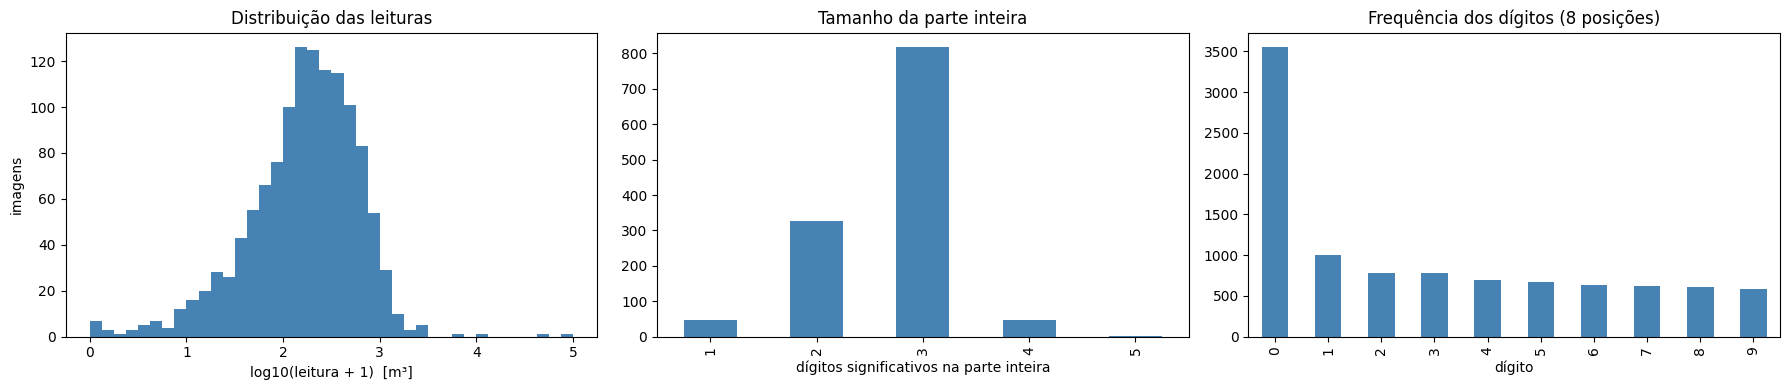

count     1243.000
mean       422.810
std       3145.578
min          0.000
25%         79.543
50%        188.816
75%        386.155
max      99999.539

Frequência dos dígitos (%): {0: 35.7, 1: 10.1, 2: 7.8, 3: 7.8, 4: 7.0, 5: 6.8, 6: 6.4, 7: 6.2, 8: 6.2, 9: 5.9}


In [12]:
valid = df[df["valid"]].copy()
vals = valid["label8"].str[:5].astype(int) + valid["label8"].str[5:].astype(int) / 1000

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(np.log10(vals + 1), bins=40, color="steelblue")
axes[0].set_xlabel("log10(leitura + 1)  [m³]")
axes[0].set_ylabel("imagens")
axes[0].set_title("Distribuição das leituras")

valid["n_int"].value_counts().sort_index().plot.bar(ax=axes[1], color="steelblue")
axes[1].set_xlabel("dígitos significativos na parte inteira")
axes[1].set_title("Tamanho da parte inteira")

digits_all = pd.Series(list("".join(valid["label8"]))).astype(int)
digits_all.value_counts().sort_index().plot.bar(ax=axes[2], color="steelblue")
axes[2].set_xlabel("dígito")
axes[2].set_title("Frequência dos dígitos (8 posições)")
plt.tight_layout()
plt.show()

print(vals.describe().round(3).to_string())
print()
print("Frequência dos dígitos (%):", (digits_all.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

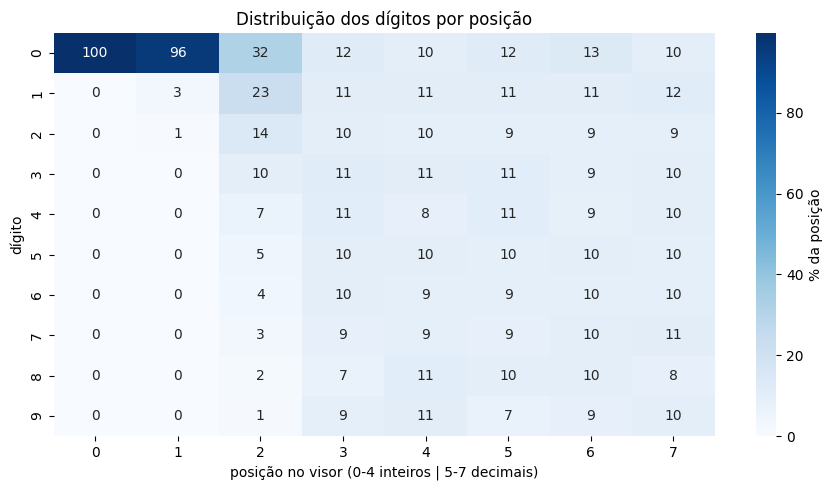

In [13]:
# Frequência de cada dígito por posição (0-4 inteiros, 5-7 decimais).
pos = np.array([list(map(int, s)) for s in valid["label8"]])
freq = pd.DataFrame({p: np.bincount(pos[:, p], minlength=10) for p in range(8)})
freq_pct = freq / freq.sum() * 100

import seaborn as sns
plt.figure(figsize=(9, 5))
sns.heatmap(freq_pct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% da posição"})
plt.xlabel("posição no visor (0-4 inteiros | 5-7 decimais)")
plt.ylabel("dígito")
plt.title("Distribuição dos dígitos por posição")
plt.tight_layout()
plt.show()

In [14]:
# Orientação do visor: razão de aspecto do retângulo mínimo do polígono (em pixels).
def display_geometry(r):
    h, w = meta_idx.loc[r.photo_name, ["h", "w"]]
    poly = polygon_px(r["loc"], h, w)
    (cx, cy), (rw, rh), ang = cv2.minAreaRect(poly)
    x, y, bw, bh = cv2.boundingRect(poly)
    return pd.Series({"bbox_aspect": bw / bh, "rect_long_short": max(rw, rh) / min(rw, rh)})

meta_idx = meta.set_index("photo_name")
geo = valid.apply(display_geometry, axis=1)
print("Visor vertical (bbox mais alto que largo):", (geo["bbox_aspect"] < 1).sum())
print("Razão lado maior / lado menor do visor:", geo["rect_long_short"].describe()[["min", "50%", "max"]].round(2).to_dict())

Visor vertical (bbox mais alto que largo): 105
Razão lado maior / lado menor do visor: {'min': 2.83, '50%': 4.99, 'max': 8.73}


**Questão 2.1**:

A coluna **value**, que é decimal -> 300 linhas têm ruído de arredondamento (ex.: 305.16200000000003);
128 linhas perderam zeros à direita.
O nome do arquivo guarda os dígitos como texto. Ele também perde zeros à direita (95_22), mas a imagem confirma que o visor mostra 00095220. Então a regra "completar a parte inteira com zeros à esquerda até 5 dígitos e a parte decimal com zeros à direita até 3" recupera o rótulo.

**Limitação dela:** 36 imagens com decimal "0" são visores de 5 dígitos, em que o rótulo de 8 dígitos não corresponde ao visor. E 1 imagem tem 4 casas decimais.

**Questão 2.2**

0: 35,7% dos recortes (3549 de 9944). O segundo é o 1, com 10,1%.
Motivo: zeros à esquerda. A leitura mediana é 188,8 m³, e 817 imagens têm parte inteira de 3 dígitos. A posição 0 é zero em 100% das imagens, a posição 1 em 96% e a posição 2 em 32%. Da posição 3 em diante, os dígitos ficam quase uniformes (~10% cada).
Implicação: a base é desbalanceada, por isso o F1-macro é a métrica certa.


## Parte 3 — Construção do dataset de dígitos

Pipeline por imagem:

1. **Retângulo do visor**: `minAreaRect` do polígono anotado; o lado maior vira o eixo horizontal (isso já endireita os visores **verticais**).
2. **Retificação**: transformação de perspectiva do retângulo para uma faixa **384×64**.
3. **Cabeça para baixo**: os 3 dígitos decimais são vermelhos e ficam à direita. Mede-se a "vermelhidão" `R − max(G, B)` nas linhas centrais da faixa, nas 3 primeiras (L) e nas 3 últimas (R) posições. A faixa é girada 180° se `L − R ≥ 1,5` **e** `(L − R)/(L + R + 1) ≥ 0,2`: a diferença absoluta ignora fundos levemente quentes e a relativa ignora visores inteiramente avermelhados. Sem evidência suficiente, mantém-se a orientação geométrica. Limiares calibrados inspecionando visualmente 37 faixas.
4. **Recortes**: 8 fatias de **48×64** de largura igual, uma por dígito.

In [15]:
import shutil

STRIP_W, STRIP_H, N_DIGITS = 384, 64, 8
CROP_W = STRIP_W // N_DIGITS
DIGITS_DIR = ROOT / "digits"
RED_MIN_DIFF = 1.5  # diferença absoluta mínima de vermelhidão (esquerda − direita)
RED_MIN_REL = 0.2   # diferença relativa mínima


def ordered_rect(poly):
    """Cantos (tl, tr, br, bl) do retângulo mínimo, com o lado maior como eixo horizontal."""
    box = cv2.boxPoints(cv2.minAreaRect(poly))
    e1, e2 = box[1] - box[0], box[2] - box[1]
    a = e1 if np.linalg.norm(e1) >= np.linalg.norm(e2) else e2
    a = a / np.linalg.norm(a)
    vertical = abs(a[1]) > abs(a[0])
    if (vertical and a[1] < 0) or (not vertical and a[0] < 0):
        a = -a  # eixo para a direita (horizontal) ou para baixo (vertical)
    p = np.array([-a[1], a[0]])
    c = box.mean(0)
    u, v = (box - c) @ a, (box - c) @ p
    tl, br = box[np.argmin(u + v)], box[np.argmax(u + v)]
    tr, bl = box[np.argmax(u - v)], box[np.argmin(u - v)]
    return np.float32([tl, tr, br, bl]), vertical


def redness_profile(strip):
    c = strip[12:52].astype(np.float32)
    return np.clip(c[..., 2] - np.maximum(c[..., 0], c[..., 1]), 0, None).mean(0)


def make_strip(img, poly):
    src, vertical = ordered_rect(poly)
    dst = np.float32([[0, 0], [STRIP_W, 0], [STRIP_W, STRIP_H], [0, STRIP_H]])
    strip = cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (STRIP_W, STRIP_H))
    red = redness_profile(strip)
    left, right = red[: 3 * CROP_W].mean(), red[-3 * CROP_W:].mean()
    red_diff, red_rel = left - right, (left - right) / (left + right + 1)
    flipped = red_diff >= RED_MIN_DIFF and red_rel >= RED_MIN_REL
    if flipped:
        strip = cv2.rotate(strip, cv2.ROTATE_180)
    return strip, {"vertical": vertical, "flipped": flipped, "red_diff": red_diff, "red_rel": red_rel}

In [16]:
# Constrói o dataset: só imagens válidas (5+3) e presentes no splits.csv oficial.
data = valid.merge(splits, on="photo_name", how="inner")
assert set(data["photo_name"]) == set(splits["photo_name"]), "splits.csv e imagens válidas divergem"

if DIGITS_DIR.exists():
    shutil.rmtree(DIGITS_DIR)

index_rows, strip_rows, strips = [], [], {}
for r in data.itertuples():
    img = imread(IMG_DIR / r.photo_name)
    strip, info = make_strip(img, polygon_px(r.loc, *img.shape[:2]))
    strips[r.photo_name] = strip
    image_id = r.photo_name.split("_value_")[0]
    strip_rows.append({"photo_name": r.photo_name, "split": r.split, **info})
    for pos, digit in enumerate(r.label8):
        out = DIGITS_DIR / r.split / digit / f"{image_id}_{pos}.png"
        out.parent.mkdir(parents=True, exist_ok=True)
        imwrite(out, strip[:, pos * CROP_W:(pos + 1) * CROP_W])
        index_rows.append({"image_id": image_id, "photo_name": r.photo_name, "position": pos,
                           "digit": int(digit), "split": r.split,
                           "crop_path": out.relative_to(ROOT).as_posix()})

index = pd.DataFrame(index_rows)
index.to_csv(DIGITS_DIR / "index.csv", index=False)
strip_info = pd.DataFrame(strip_rows)
print(f"{len(strips)} faixas, {len(index)} recortes salvos em {DIGITS_DIR}")

1243 faixas, 9944 recortes salvos em /content/digits


In [17]:
# Verificações obrigatórias.
n_valid, n_discarded = len(data), int((~df["valid"]).sum())
n_files = sum(1 for _ in DIGITS_DIR.glob("*/*/*.png"))
splits_per_image = index.groupby("photo_name")["split"].nunique()
crop_shapes = {imread(ROOT / p).shape for p in index["crop_path"].sample(200, random_state=SEED)}

checks3 = {
    "1243 imagens válidas": n_valid == 1243,
    "1 imagem descartada": n_discarded == 1,
    "9944 recortes no índice": len(index) == 9944,
    "9944 arquivos em disco": n_files == 9944,
    "nenhuma imagem em mais de um split": (splits_per_image == 1).all(),
    "8 recortes por imagem": (index.groupby("photo_name").size() == 8).all(),
    "recortes 64x48x3": crop_shapes == {(64, 48, 3)},
}
for k, v in checks3.items():
    print(f"[{'OK' if v else 'FALHA'}] {k}")
assert all(checks3.values())
print()
print(pd.crosstab(index["digit"], index["split"], margins=True).T.to_string())

[OK] 1243 imagens válidas
[OK] 1 imagem descartada
[OK] 9944 recortes no índice
[OK] 9944 arquivos em disco
[OK] nenhuma imagem em mais de um split
[OK] 8 recortes por imagem
[OK] recortes 64x48x3

digit     0     1    2    3    4    5    6    7    8    9   All
split                                                          
test    515   150  130  111  113   96  109   75  112   85  1496
train  2482   718  525  553  488  480  450  450  400  414  6960
val     552   135  122  115   97  101   79   95  101   91  1488
All    3549  1003  777  779  698  677  638  620  613  590  9944


In [18]:
# Correção de orientação e recortes suspeitos.
si = strip_info.merge(df[["photo_name", "dec_part"]], on="photo_name")
si["corrected"] = si["vertical"] | si["flipped"]
si["ambiguous"] = si["red_diff"].abs() < RED_MIN_DIFF  # sem diferença de vermelho entre as pontas
si["five_digit_display"] = si["dec_part"] == "0"

print("Faixas corrigidas:", si["corrected"].sum())
print("  verticais rotacionadas 90°:", si["vertical"].sum())
print("  giradas 180° (cabeça para baixo):", si["flipped"].sum(),
      f"(das quais {(si.vertical & si.flipped).sum()} também eram verticais)")
print()
print(pd.crosstab(si["vertical"], si["flipped"], rownames=["vertical"], colnames=["girada 180°"]).to_string())
print()
print("Orientação ambígua (sem vermelho para decidir):", si["ambiguous"].sum())
print("Rótulo decimal '0' (visor de 5 dígitos provável):", si["five_digit_display"].sum(),
      "->", si["five_digit_display"].sum() * 8, "recortes desalinhados com o rótulo")
print(si.groupby("split")[["corrected", "ambiguous", "five_digit_display"]].sum().to_string())

Faixas corrigidas: 118
  verticais rotacionadas 90°: 105
  giradas 180° (cabeça para baixo): 54 (das quais 41 também eram verticais)

girada 180°  False  True 
vertical                 
False         1125     13
True            64     41

Orientação ambígua (sem vermelho para decidir): 39
Rótulo decimal '0' (visor de 5 dígitos provável): 36 -> 288 recortes desalinhados com o rótulo
       corrected  ambiguous  five_digit_display
split                                          
test          15          7                   4
train         82         24                  23
val           21          8                   9


> ⚠️ As células abaixo exibem recortes do dataset: **limpar a saída antes do commit**.

In [19]:
def show_strips(names, title, ncol=3):
    nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.5 * ncol, 1.3 * nrow))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, n in zip(np.atleast_1d(axes).ravel(), names):
        ax.imshow(cv2.cvtColor(strips[n], cv2.COLOR_BGR2RGB))
        for k in range(1, N_DIGITS):
            ax.axvline(k * CROP_W, color="cyan", lw=0.8)
        ax.set_title(df.set_index("photo_name").loc[n, "label8"], fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
pick = lambda mask, k=9: list(rng.choice(si.loc[mask, "photo_name"], min(k, mask.sum()), replace=False))
show_strips(pick(~si["corrected"]), "Faixas sem correção")
show_strips(pick(si["vertical"]), "Visores verticais (rotacionados)")
show_strips(pick(si["flipped"] & ~si["vertical"]), "Visores de cabeça para baixo (girados 180°)")
show_strips(pick(si["ambiguous"]), "Orientação ambígua (sem vermelho)")
show_strips(pick(si["five_digit_display"]), "Rótulo decimal '0': visores de 5 dígitos")

In [20]:
# Os 8 recortes de uma imagem, lidos do disco.
ex = index[index["photo_name"] == data["photo_name"].iloc[0]]
fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for ax, r in zip(axes, ex.itertuples()):
    ax.imshow(cv2.cvtColor(imread(ROOT / r.crop_path), cv2.COLOR_BGR2RGB))
    ax.set_title(f"pos {r.position}: {r.digit}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Questão 3.1**

Os 8 recortes de uma foto compartilham hidrômetro, fonte, iluminação, fundo e desfoque. Se recortes da mesma foto estivessem no treino e no teste, o modelo "reconheceria o hidrômetro" e o teste ficaria otimista (data leakage). 

A acc_reading também exige os 8 recortes da imagem no mesmo split.

O mesmo splits.csv para todos garante comparação justa entre os modelos e entre os grupos, e impede escolher um split favorável.


**Questão 3.2** 

**118 faixas corrigidas:**
- 105 verticais (rotação de 90°);
- 54 giradas 180°, das quais 41 eram verticais e 13 eram horizontais de cabeça para baixo.

Tipos de erro, com quantidades:

- **Visor de 5 dígitos:** 36 imagens, 288 recortes desalinhados do rótulo. No teste (4 imagens), os modelos pré-treinados acertam só 53–56% desses recortes.

- **Orientação ambígua (sem vermelho para decidir):** 39 faixas. Em 37 faixas conferidas à mão, 2 estavam erradas (1227_0 e 509_0, ambas sem vermelho). No teste (7 imagens), a acurácia nesse grupo é de 68–75%.

- **Desalinhamento pela divisão em larguras iguais:** recortes com meio dígito, com o vizinho ou com a vírgula. Isso não foi contado diretamente.

- **Dígito rolando na última posição decimal:** a acurácia na posição 7 é 0,88 na ResNet18, contra 0,95–0,99 nas outras posições.



**Questão 3.3**

A divisão supõe que os 8 dígitos são igualmente espaçados e preenchem o polígono inteiro. Isso falha por vários motivos:
  margens do polígono;
  a vírgula e as janelas vermelhas com espaçamento diferente;
  perspectiva: o minAreaRect não corrige a perspectiva, então os dígitos do lado mais distante ficam mais estreitos;
  visores de 5 dígitos.

O deslocamento se acumula e piora nas pontas.
como corrigir:
  usar o perfil de projeção vertical ou componentes conexos para achar os espaços entre os tambores;
  fazer a homografia com os 4 cantos reais do polígono (approxPolyDP) em vez do retângulo mínimo;
  detectar se o visor tem 5 ou 8 dígitos;
  ou não cortar: usar um modelo de sequência (CRNN com CTC). Esse é o desafio extra.
 

## Parte 4 — Treinamento dos quatro modelos

| Modelo | Pesos | Entrada (A×L) | Batch CUDA / outro | LR cabeça | LR backbone | Épocas |
|---|---|---|---|---|---|---|
| `smallcnn` | do zero | 64×48 | 256 / 128 | 1e-3 | — | 10 |
| `alexnet` | IMAGENET1K_V1 | 128×128 | 128 / 64 | 1e-3 | 1e-4 | 8 |
| `vgg16_bn` | IMAGENET1K_V1 | 128×128 | 32 / 16 | 1e-3 | 1e-5 | 8 |
| `resnet18` | IMAGENET1K_V1 | 128×128 | 128 / 64 | 1e-3 | 1e-4 | 8 |

Comum a todos: `AdamW` + `OneCycleLR` (por passo), `CrossEntropyLoss(label_smoothing=0.1)`, 1ª época com backbone congelado (pré-treinados), *early stopping* pelo F1-macro de validação (paciência 3), `seed=42`, augmentation `RandomAffine(5, (0.05, 0.05), (0.95, 1.05))` + `ColorJitter(0.3, 0.3)` sem flip, normalização ImageNet.

Detalhes de implementação (iguais para os quatro):

- a **cabeça** é a camada linear final substituída (10 classes); todo o resto é **backbone**;
- treino em **fp32**: mixed precision (fp16) produziu loss `NaN` desde a 1ª época na GTX 1650 (problema conhecido das GPUs da série 16xx), por isso foi desligada;
- *augmentation* aplicada **na GPU, por lote**, com parâmetros sorteados por amostra (mesmos intervalos de `RandomAffine` e `ColorJitter` do protocolo). Feita por imagem na CPU, ela era o gargalo (~150 s por época na `smallcnn`);
- `seconds` mede só o laço de treino, sem validação.

In [21]:
import math
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader, TensorDataset
from torchvision import models

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
CKPT_DIR = ROOT / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
NUM_CLASSES = 10
PATIENCE = 3
LABEL_SMOOTHING = 0.1
FREEZE_EPOCHS = 1
RETRAIN = False  # True força retreinar mesmo se já houver checkpoint e histórico

PROTOCOL = {
    "smallcnn": dict(weights=None, size=(64, 48), batch=(256, 128), lr_head=1e-3, lr_backbone=None, epochs=10),
    "alexnet": dict(weights="IMAGENET1K_V1", size=(128, 128), batch=(128, 64), lr_head=1e-3, lr_backbone=1e-4, epochs=8),
    "vgg16_bn": dict(weights="IMAGENET1K_V1", size=(128, 128), batch=(32, 16), lr_head=1e-3, lr_backbone=1e-5, epochs=8),
    "resnet18": dict(weights="IMAGENET1K_V1", size=(128, 128), batch=(128, 64), lr_head=1e-3, lr_backbone=1e-4, epochs=8),
}
MODELS = list(PROTOCOL)

print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

Dispositivo: cuda Tesla T4
torch 2.11.0+cu130


In [22]:
# Recortes carregados uma vez em memória (uint8, RGB, 3×64×48).
def load_split(split):
    sub = index[index["split"] == split].reset_index(drop=True)
    x = np.stack([cv2.cvtColor(imread(ROOT / p), cv2.COLOR_BGR2RGB) for p in sub["crop_path"]])
    return sub, torch.from_numpy(x).permute(0, 3, 1, 2).contiguous(), torch.tensor(sub["digit"].values)


SPLIT_DATA = {s: load_split(s) for s in ("train", "val", "test")}
for s, (sub, x, y) in SPLIT_DATA.items():
    print(f"{s:<5} {tuple(x.shape)}  imagens={sub['photo_name'].nunique()}")


MEAN_T = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T = torch.tensor(IMAGENET_STD, device=DEVICE).view(1, 3, 1, 1)


def random_affine(x, degrees=5, translate=(0.05, 0.05), scale=(0.95, 1.05)):
    """Equivalente a v2.RandomAffine, com parâmetros sorteados por amostra."""
    n, _, h, w = x.shape
    u = lambda lo, hi: torch.empty(n, device=x.device).uniform_(lo, hi)
    ang, s = u(-degrees, degrees) * math.pi / 180, u(*scale)
    tx, ty = u(-translate[0], translate[0]) * 2, u(-translate[1], translate[1]) * 2  # em coords normalizadas
    cos, sin, r = torch.cos(ang), torch.sin(ang), h / w
    theta = torch.stack([
        torch.stack([cos / s, sin * r / s, (-cos * tx - sin * r * ty) / s], 1),
        torch.stack([-sin / r / s, cos / s, (sin / r * tx - cos * ty) / s], 1),
    ], 1)  # mapeamento inverso (saída -> entrada) em coordenadas normalizadas, corrigido pelo aspecto
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)


def color_jitter(x, brightness=0.3, contrast=0.3):
    """Equivalente a v2.ColorJitter(brightness, contrast), por amostra."""
    n = x.shape[0]
    b = torch.empty(n, 1, 1, 1, device=x.device).uniform_(1 - brightness, 1 + brightness)
    c = torch.empty(n, 1, 1, 1, device=x.device).uniform_(1 - contrast, 1 + contrast)
    x = (x * b).clamp(0, 1)
    gray = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).mean((1, 2)).view(n, 1, 1, 1)
    return ((x - gray) * c + gray).clamp(0, 1)


def prepare_batch(x, size, train):
    """uint8 (N, 3, 64, 48) -> float normalizado no tamanho de entrada do modelo, na GPU."""
    x = x.to(DEVICE, non_blocking=True).float() / 255
    if tuple(x.shape[-2:]) != tuple(size):
        x = F.interpolate(x, size=size, mode="bilinear", align_corners=False, antialias=True)
    if train:
        x = color_jitter(random_affine(x))
    return (x - MEAN_T) / STD_T


def make_loader(name, split, train=False, batch_size=None):
    cfg = PROTOCOL[name]
    _, x, y = SPLIT_DATA[split]
    bs = batch_size or cfg["batch"][0 if DEVICE.type == "cuda" else 1]
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(TensorDataset(x, y), batch_size=bs, shuffle=train, generator=gen,
                      num_workers=0, pin_memory=DEVICE.type == "cuda")

train (6960, 3, 64, 48)  imagens=870
val   (1488, 3, 64, 48)  imagens=186
test  (1496, 3, 64, 48)  imagens=187


In [23]:
class SmallCNN(nn.Module):
    """CNN pequena treinada do zero para recortes 64×48."""

    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
                                        nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def build_model(name, pretrained=True):
    """Retorna (modelo, módulo da cabeça). A cabeça é a camada final nova; o resto é backbone."""
    w = PROTOCOL[name]["weights"] if pretrained else None
    if name == "smallcnn":
        m = SmallCNN()
        return m, m
    if name == "alexnet":
        m = models.alexnet(weights=w)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, NUM_CLASSES)
        return m, m.classifier[6]
    if name == "vgg16_bn":
        m = models.vgg16_bn(weights=w)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, NUM_CLASSES)
        return m, m.classifier[6]
    if name == "resnet18":
        m = models.resnet18(weights=w)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        return m, m.fc
    raise ValueError(name)


def count_params(module):
    return sum(p.numel() for p in module.parameters())

In [24]:
# Questão 4.2: onde estão os parâmetros?
def first_linear(module):
    return next(m for m in module.modules() if isinstance(m, nn.Linear))


rows = []
for name in MODELS:
    m, head = build_model(name, pretrained=False)
    total = count_params(m)
    fc = count_params(m.fc) if name == "resnet18" else count_params(m.classifier)
    rows.append({"model": name, "params_M": total / 1e6, "conv_M": (total - fc) / 1e6, "fc_M": fc / 1e6,
                 "fc_%": 100 * fc / total, "1ª_linear_M": count_params(first_linear(m)) / 1e6})
params_table = pd.DataFrame(rows).set_index("model")
params_table.round(3)

,params_M,conv_M,fc_M,fc_%,1ª_linear_M
model,,,,,
smallcnn,0.289,0.287,0.001,0.447,0.001
alexnet,57.045,2.470,54.575,95.671,37.753
vgg16_bn,134.310,14.723,119.587,89.038,102.765
resnet18,11.182,11.177,0.005,0.046,0.005


In [25]:
def run_epoch(model, loader, criterion, size, optimizer=None, scheduler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, preds, targets = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = prepare_batch(x, size, train), y.to(DEVICE, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
                scheduler.step()
            total_loss += loss.item() * len(y)
            preds.append(out.argmax(1).cpu())
            targets.append(y.cpu())
    p, t = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    return total_loss / len(t), float((p == t).mean()), float(f1_score(t, p, average="macro"))


def train_model(name):
    cfg = PROTOCOL[name]
    ckpt_path, hist_path = CKPT_DIR / f"{name}.pt", ROOT / f"history_{name}.csv"
    if not RETRAIN and ckpt_path.exists() and hist_path.exists():
        print(f"{name}: checkpoint e histórico já existem, pulando treino.")
        return pd.read_csv(hist_path)

    seed_everything(SEED)
    model, head = build_model(name)
    model.to(DEVICE)
    head_ids = {id(p) for p in head.parameters()}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    groups = [{"params": list(head.parameters()), "lr": cfg["lr_head"]}]
    if backbone:
        groups.insert(0, {"params": backbone, "lr": cfg["lr_backbone"]})

    train_loader = make_loader(name, "train", train=True)
    val_loader = make_loader(name, "val")
    optimizer = torch.optim.AdamW(groups)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=[g["lr"] for g in groups], total_steps=cfg["epochs"] * len(train_loader))
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

    history, best_f1, bad = [], -1.0, 0
    for epoch in range(1, cfg["epochs"] + 1):
        frozen = bool(backbone) and epoch <= FREEZE_EPOCHS
        for p in backbone:
            p.requires_grad_(not frozen)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        tr_loss, tr_acc, _ = run_epoch(model, train_loader, criterion, cfg["size"], optimizer, scheduler)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        seconds = time.perf_counter() - t0
        va_loss, va_acc, va_f1 = run_epoch(model, val_loader, criterion, cfg["size"])

        history.append({"epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss,
                        "val_acc": va_acc, "val_f1": va_f1, "seconds": seconds})
        improved = va_f1 > best_f1
        print(f"{name} ep {epoch:>2}{' [congelado]' if frozen else ''}: "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} "
              f"f1 {va_f1:.4f} | {seconds:.1f}s{'  *' if improved else ''}")
        if improved:
            best_f1, bad = va_f1, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"{name}: early stopping na época {epoch}")
                break

    hist = pd.DataFrame(history)
    hist.to_csv(hist_path, index=False)
    del model, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return hist

In [26]:
histories = {}
for name in MODELS:
    histories[name] = train_model(name)
    h = histories[name]
    print(f"--> {name}: melhor F1 val {h['val_f1'].max():.4f} na época {int(h.loc[h['val_f1'].idxmax(), 'epoch'])}\n")

smallcnn ep  1: train loss 2.3318 acc 0.1761 | val loss 2.2966 acc 0.1747 f1 0.0802 | 5.9s  *
smallcnn ep  2: train loss 2.0899 acc 0.3480 | val loss 2.0933 acc 0.3589 f1 0.0638 | 2.8s
smallcnn ep  3: train loss 2.0007 acc 0.3624 | val loss 1.9407 acc 0.3763 f1 0.0910 | 2.9s  *
smallcnn ep  4: train loss 1.8569 acc 0.4109 | val loss 1.8831 acc 0.3871 f1 0.0984 | 2.9s  *
smallcnn ep  5: train loss 1.6386 acc 0.5053 | val loss 1.5322 acc 0.5544 f1 0.3767 | 2.9s  *
smallcnn ep  6: train loss 1.4680 acc 0.5953 | val loss 1.4409 acc 0.5659 f1 0.3825 | 2.9s  *
smallcnn ep  7: train loss 1.3253 acc 0.6846 | val loss 1.3750 acc 0.6022 f1 0.4569 | 2.9s  *
smallcnn ep  8: train loss 1.2431 acc 0.7345 | val loss 1.2547 acc 0.7500 f1 0.6504 | 2.9s  *
smallcnn ep  9: train loss 1.1953 acc 0.7580 | val loss 1.1562 acc 0.7863 f1 0.7254 | 2.9s  *
smallcnn ep 10: train loss 1.1687 acc 0.7737 | val loss 1.1401 acc 0.8065 f1 0.7476 | 2.9s  *
--> smallcnn: melhor F1 val 0.7476 na época 10

Downloading: "h

100%|██████████| 233M/233M [00:01<00:00, 178MB/s]


alexnet ep  1 [congelado]: train loss 2.0104 acc 0.3473 | val loss 1.5875 acc 0.5269 f1 0.3607 | 1.3s  *
alexnet ep  2: train loss 1.2690 acc 0.6874 | val loss 0.9781 acc 0.8199 f1 0.7597 | 3.6s  *
alexnet ep  3: train loss 0.9288 acc 0.8415 | val loss 0.8331 acc 0.8831 f1 0.8475 | 3.6s  *
alexnet ep  4: train loss 0.7952 acc 0.8996 | val loss 0.8027 acc 0.8958 f1 0.8684 | 3.6s  *
alexnet ep  5: train loss 0.7227 acc 0.9282 | val loss 0.7687 acc 0.9079 f1 0.8823 | 3.6s  *
alexnet ep  6: train loss 0.6739 acc 0.9487 | val loss 0.7477 acc 0.9194 f1 0.8965 | 3.6s  *
alexnet ep  7: train loss 0.6525 acc 0.9559 | val loss 0.7357 acc 0.9220 f1 0.8993 | 3.7s  *
alexnet ep  8: train loss 0.6426 acc 0.9612 | val loss 0.7379 acc 0.9214 f1 0.8979 | 3.6s
--> alexnet: melhor F1 val 0.8993 na época 7

Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:07<00:00, 74.2MB/s]


vgg16_bn ep  1 [congelado]: train loss 1.9201 acc 0.3907 | val loss 1.5717 acc 0.5659 f1 0.3840 | 13.3s  *
vgg16_bn ep  2: train loss 1.2603 acc 0.6869 | val loss 0.9626 acc 0.8340 f1 0.7887 | 47.4s  *
vgg16_bn ep  3: train loss 0.8758 acc 0.8766 | val loss 0.7873 acc 0.9005 f1 0.8810 | 47.4s  *
vgg16_bn ep  4: train loss 0.7474 acc 0.9260 | val loss 0.7364 acc 0.9214 f1 0.9050 | 47.3s  *
vgg16_bn ep  5: train loss 0.6923 acc 0.9444 | val loss 0.7044 acc 0.9328 f1 0.9188 | 47.5s  *
vgg16_bn ep  6: train loss 0.6589 acc 0.9562 | val loss 0.6926 acc 0.9375 f1 0.9257 | 47.4s  *
vgg16_bn ep  7: train loss 0.6470 acc 0.9579 | val loss 0.6847 acc 0.9402 f1 0.9290 | 47.4s  *
vgg16_bn ep  8: train loss 0.6372 acc 0.9641 | val loss 0.6853 acc 0.9409 f1 0.9311 | 47.5s  *
--> vgg16_bn: melhor F1 val 0.9311 na época 8

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 16.5MB/s]


resnet18 ep  1 [congelado]: train loss 2.3699 acc 0.2145 | val loss 2.1333 acc 0.3683 f1 0.0835 | 3.0s  *
resnet18 ep  2: train loss 1.3532 acc 0.6556 | val loss 0.8600 acc 0.8824 f1 0.8546 | 9.1s  *
resnet18 ep  3: train loss 0.7497 acc 0.9187 | val loss 0.7063 acc 0.9415 f1 0.9288 | 9.3s  *
resnet18 ep  4: train loss 0.6404 acc 0.9580 | val loss 0.6754 acc 0.9469 f1 0.9367 | 9.4s  *
resnet18 ep  5: train loss 0.5976 acc 0.9749 | val loss 0.6589 acc 0.9496 f1 0.9410 | 9.4s  *
resnet18 ep  6: train loss 0.5689 acc 0.9848 | val loss 0.6464 acc 0.9543 f1 0.9472 | 9.3s  *
resnet18 ep  7: train loss 0.5588 acc 0.9876 | val loss 0.6452 acc 0.9583 f1 0.9524 | 9.3s  *
resnet18 ep  8: train loss 0.5541 acc 0.9904 | val loss 0.6471 acc 0.9583 f1 0.9513 | 9.2s
--> resnet18: melhor F1 val 0.9524 na época 7



**Questão 4.1**

Os pesos pré-treinados foram aprendidos com entradas normalizadas por essa média e esse desvio padrão. Os filtros da 1ª camada e as estatísticas de BatchNorm  meio que esperam essa distribuição. Sem a normalização, as ativações ficam deslocadas e as features perdem sentido.

*A smallcnn usou a mesma normalização só para manter o protocolo idêntico.


**Questão 4.2**

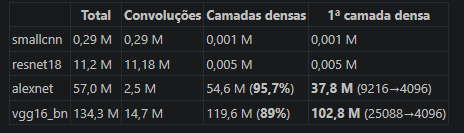
- Na AlexNet e na VGG16, quase todos os parâmetros estão na 1ª camada densa.
- A ResNet usa global average pooling, então quase não tem camada densa.
- O tamanho do checkpoint acompanha os parâmetros: 1, 43, 218 e 512 MB.


**Questão 4.3**

**Só a cabeça:** as features ficam fixas, as do ImageNet, e só o classificador novo aprende.
**Fine-tuning:** a rede inteira se adapta aos dígitos, com LR menor no backbone.

Os números mostram a diferença. F1 de validação na época 1, com backbone congelado:
- AlexNet 0,36, VGG16 0,38, ResNet18 0,08.

Na época 2, já descongelado: 0,76, 0,79 e 0,85. No final: 0,90, 0,93 e 0,95.

Por que congelar só na 1ª época: a cabeça começa aleatória, e os gradientes grandes do começo destruiriam as features pré-treinadas. Primeiro a cabeça "aquece", depois a rede toda se adapta, porque dígito de hidrômetro está longe do domínio do ImageNet.

**Questão 4.4**
- O flip horizontal cria símbolos que não existem (2, 3, 5 e 7 espelhados).

- O flip vertical ou a rotação de 180° troca 6↔9 e inverte a ordem e a posição das casas decimais.

- Hidrômetros nunca aparecem espelhados. A augmentation deve imitar variações plausíveis, por isso a rotação é só de ±5°.


## Parte 5 — Avaliação no conjunto de teste

Todas as métricas abaixo usam o **teste**; a validação serviu apenas para o *early stopping*. Cada modelo é avaliado com o checkpoint da melhor época (maior F1-macro de validação).

In [27]:
from sklearn.metrics import classification_report, confusion_matrix


def load_best(name):
    model, _ = build_model(name, pretrained=False)
    model.load_state_dict(torch.load(CKPT_DIR / f"{name}.pt", map_location=DEVICE))
    return model.to(DEVICE).eval()


@torch.no_grad()
def predict(model, loader, size):
    probs = []
    for x, _ in loader:
        probs.append(torch.softmax(model(prepare_batch(x, size, train=False)), 1).cpu())
    return torch.cat(probs).numpy()


@torch.no_grad()
def time_inference(model, size, n_warmup=20, n_runs=200):
    """Batch 1: mediana de n_runs execuções após n_warmup de aquecimento, em ms."""
    x = torch.randn(1, 3, *size, device=DEVICE)
    times = []
    for i in range(n_warmup + n_runs):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        model(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        if i >= n_warmup:
            times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times))


test_index = SPLIT_DATA["test"][0]
y_test = SPLIT_DATA["test"][2].numpy()
preds, results = {}, []
for name in MODELS:
    model = load_best(name)
    prob = predict(model, make_loader(name, "test"), PROTOCOL[name]["size"])
    pred = prob.argmax(1)
    preds[name] = prob
    hist = pd.read_csv(ROOT / f"history_{name}.csv")
    correct = pd.Series(pred == y_test).groupby(test_index["photo_name"].values).all()
    results.append({
        "model": name,
        "acc_digit": float((pred == y_test).mean()),
        "f1_macro": float(f1_score(y_test, pred, average="macro")),
        "acc_reading": float(correct.mean()),
        "params_M": count_params(model) / 1e6,
        "s_per_epoch": float(hist["seconds"].median()),
        "ms_per_image": time_inference(model, PROTOCOL[name]["size"]),
        "ckpt_MB": (CKPT_DIR / f"{name}.pt").stat().st_size / 2**20,
        "best_epoch": int(hist.loc[hist["val_f1"].idxmax(), "epoch"]),
    })
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results).round(4)
results_df.to_csv(ROOT / "results.csv", index=False)
results_df

,model,acc_digit,f1_macro,acc_reading,params_M,s_per_epoch,ms_per_image,ckpt_MB,best_epoch
0,smallcnn,0.7955,0.7502,0.2834,0.2887,2.8850,0.7690,1.1177,10
1,alexnet,0.9258,0.9075,0.6257,57.0448,3.5801,1.7846,217.6142,7
2,vgg16_bn,0.9459,0.9379,0.7166,134.3100,47.3884,7.5516,512.4149,8
3,resnet18,0.9612,0.9543,0.7968,11.1816,9.2626,2.6246,42.7302,7


In [28]:
for name in MODELS:
    print(f"=== {name} ===")
    print(classification_report(y_test, preds[name].argmax(1), digits=4))

=== smallcnn ===
              precision    recall  f1-score   support

           0     0.7943    0.9670    0.8722       515
           1     0.7692    0.8000    0.7843       150
           2     0.8824    0.8077    0.8434       130
           3     0.6953    0.8018    0.7448       111
           4     0.7909    0.7699    0.7803       113
           5     0.7684    0.7604    0.7644        96
           6     0.7463    0.4587    0.5682       109
           7     0.8841    0.8133    0.8472        75
           8     0.8256    0.6339    0.7172       112
           9     0.9231    0.4235    0.5806        85

    accuracy                         0.7955      1496
   macro avg     0.8079    0.7236    0.7502      1496
weighted avg     0.8008    0.7955    0.7860      1496

=== alexnet ===
              precision    recall  f1-score   support

           0     0.9580    0.9748    0.9663       515
           1     0.9384    0.9133    0.9257       150
           2     0.9313    0.9385    0.9349  

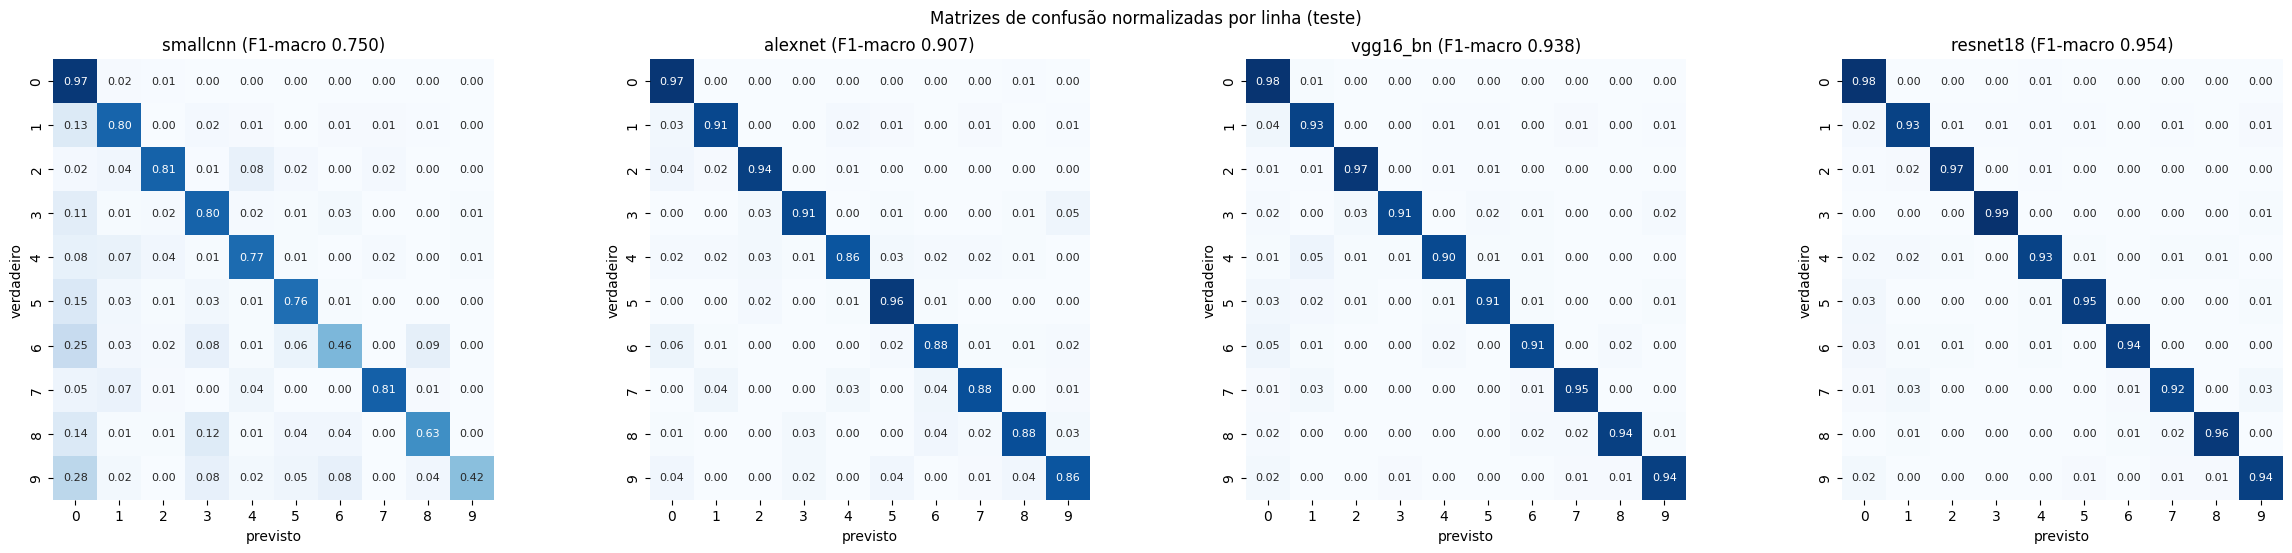

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(y_test, preds[name].argmax(1), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                annot_kws={"size": 8}, square=True)
    f1 = results_df.set_index("model").loc[name, "f1_macro"]
    ax.set_title(f"{name} (F1-macro {f1:.3f})")
    ax.set_xlabel("previsto")
    ax.set_ylabel("verdadeiro")
plt.suptitle("Matrizes de confusão normalizadas por linha (teste)")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
# Pares de classes mais confundidos (contagens no teste, somando os quatro modelos).
pairs = []
for name in MODELS:
    cm = confusion_matrix(y_test, preds[name].argmax(1))
    np.fill_diagonal(cm, 0)
    for t, p in zip(*np.nonzero(cm)):
        pairs.append({"model": name, "verdadeiro": t, "previsto": p, "n": cm[t, p]})
pairs = pd.DataFrame(pairs)
top_pairs = (pairs.pivot_table(index=["verdadeiro", "previsto"], columns="model", values="n", fill_value=0)
             [MODELS].assign(total=lambda d: d.sum(1)).sort_values("total", ascending=False))
top_pairs.head(10)

,model,smallcnn,alexnet,vgg16_bn,resnet18,total
verdadeiro,previsto,,,,,
6,0,27.0,6.0,5.0,3.0,41.0
1,0,20.0,5.0,6.0,3.0,34.0
9,0,24.0,3.0,2.0,2.0,31.0
5,0,14.0,0.0,3.0,3.0,20.0
8,0,16.0,1.0,2.0,0.0,19.0
4,1,8.0,2.0,6.0,2.0,18.0
8,3,14.0,3.0,0.0,0.0,17.0
0,1,8.0,1.0,5.0,1.0,15.0
4,0,9.0,2.0,1.0,2.0,14.0


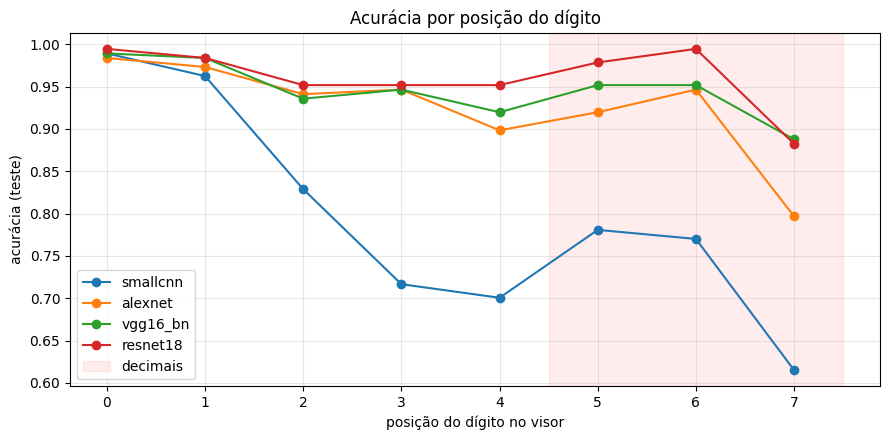

,smallcnn,alexnet,vgg16_bn,resnet18
0,0.9893,0.9840,0.9893,0.9947
1,0.9626,0.9733,0.9840,0.9840
2,0.8289,0.9412,0.9358,0.9519
3,0.7166,0.9465,0.9465,0.9519
4,0.7005,0.8984,0.9198,0.9519
5,0.7807,0.9198,0.9519,0.9786
6,0.7701,0.9465,0.9519,0.9947
7,0.6150,0.7968,0.8877,0.8824


In [31]:
pos_acc = pd.DataFrame({name: pd.Series(preds[name].argmax(1) == y_test).groupby(test_index["position"].values).mean()
                        for name in MODELS})
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in MODELS:
    ax.plot(pos_acc.index, pos_acc[name], marker="o", label=name)
ax.axvspan(4.5, 7.5, color="red", alpha=0.07, label="decimais")
ax.set_xticks(range(8))
ax.set_xlabel("posição do dígito no visor")
ax.set_ylabel("acurácia (teste)")
ax.set_title("Acurácia por posição do dígito")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "accuracy_by_position.png", dpi=150, bbox_inches="tight")
plt.show()
pos_acc.round(4)

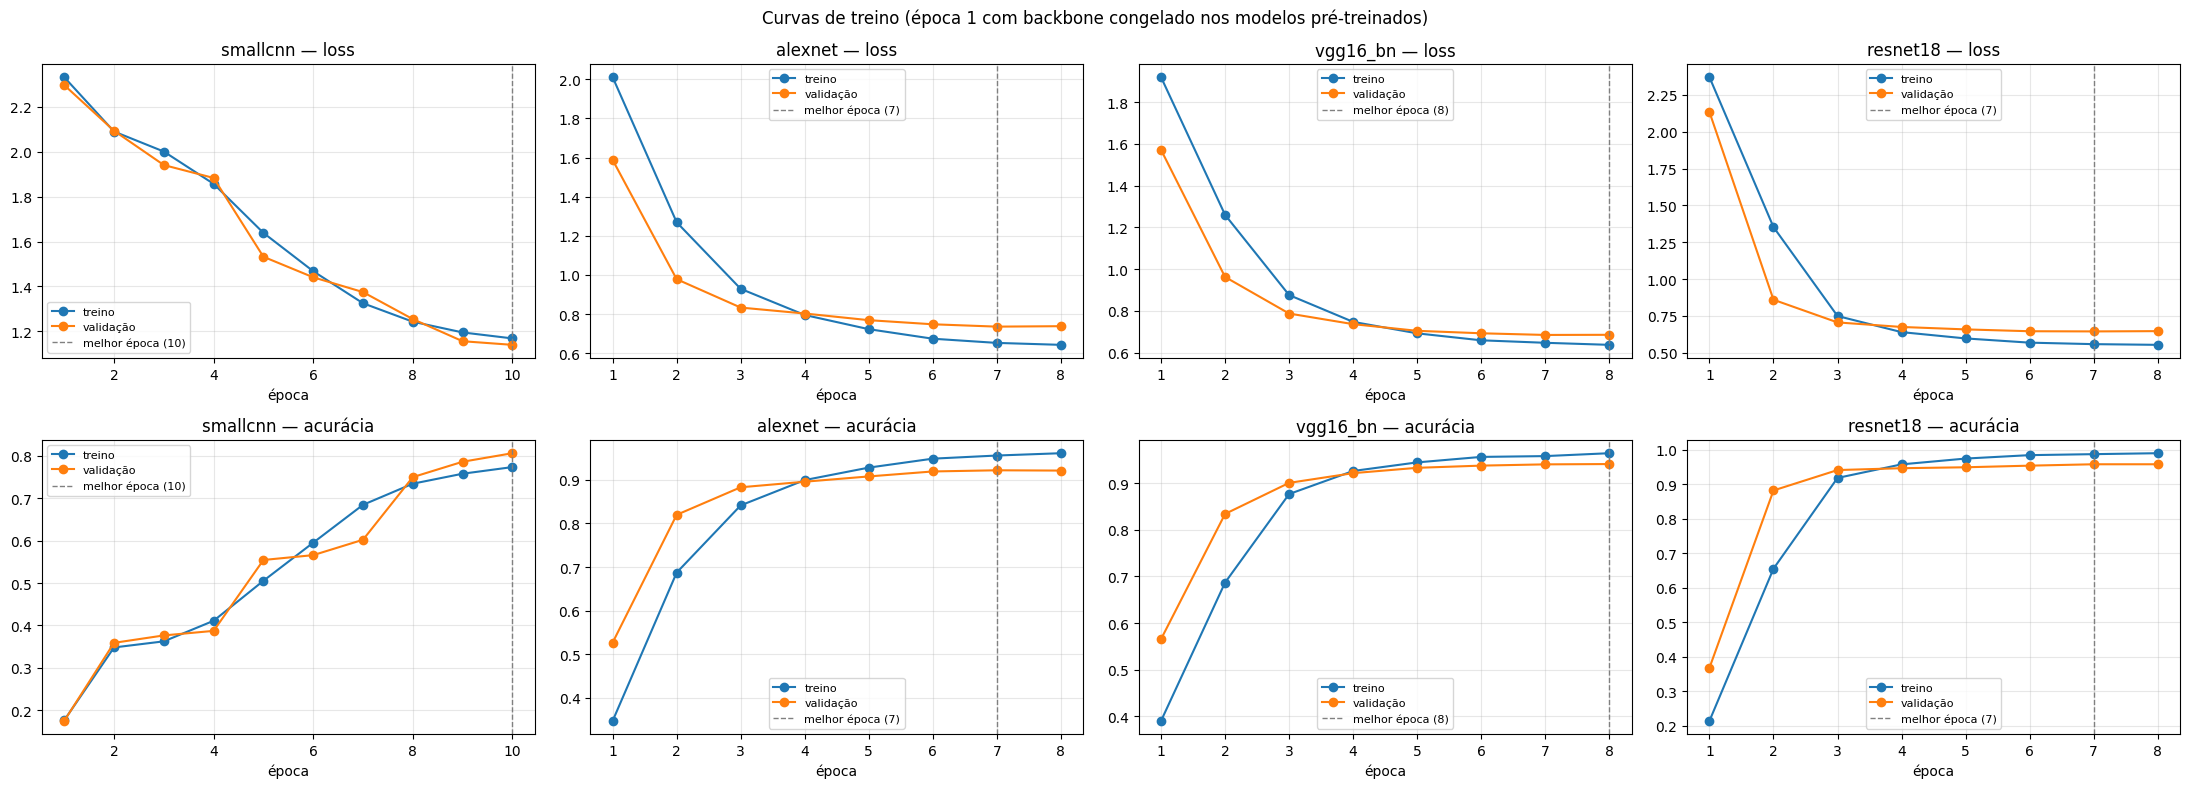

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(22, 8), sharex=False)
for j, name in enumerate(MODELS):
    h = pd.read_csv(ROOT / f"history_{name}.csv")
    best = h.loc[h["val_f1"].idxmax(), "epoch"]
    for i, (metric, label) in enumerate([("loss", "loss"), ("acc", "acurácia")]):
        ax = axes[i, j]
        ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", label="treino")
        ax.plot(h["epoch"], h[f"val_{metric}"], marker="o", label="validação")
        ax.axvline(best, color="gray", ls="--", lw=1, label=f"melhor época ({best})")
        ax.set_title(f"{name} — {label}")
        ax.set_xlabel("época")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
plt.suptitle("Curvas de treino (época 1 com backbone congelado nos modelos pré-treinados)")
plt.tight_layout()
plt.savefig(FIG_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

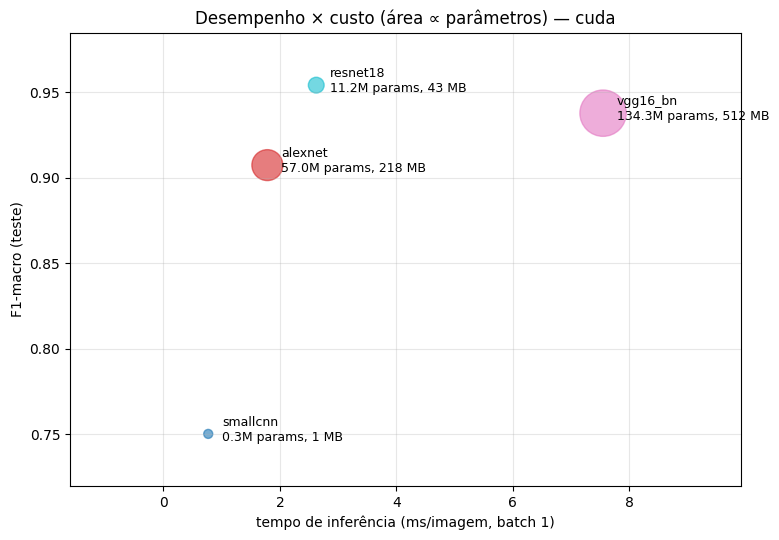

In [33]:
r = results_df.set_index("model")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(r["ms_per_image"], r["f1_macro"], s=40 + 8 * r["params_M"], alpha=0.6, c=range(len(r)), cmap="tab10")
for name, row in r.iterrows():
    ax.annotate(f"{name}\n{row.params_M:.1f}M params, {row.ckpt_MB:.0f} MB",
                (row.ms_per_image, row.f1_macro), textcoords="offset points", xytext=(10, -5), fontsize=9)
ax.set_xlabel("tempo de inferência (ms/imagem, batch 1)")
ax.set_ylabel("F1-macro (teste)")
ax.set_title(f"Desempenho × custo (área ∝ parâmetros) — {DEVICE.type}")
ax.grid(alpha=0.3)
ax.margins(x=0.35, y=0.15)
plt.tight_layout()
plt.savefig(FIG_DIR / "performance_vs_cost.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
# Erro por tipo de recorte: quanto do erro vem do pipeline de dados?
ti = test_index.merge(si[["photo_name", "corrected", "ambiguous", "five_digit_display"]], on="photo_name")
groups = {
    "todos": np.ones(len(ti), bool),
    "visor de 5 dígitos (rótulo decimal '0')": ti["five_digit_display"].values,
    "orientação ambígua": ti["ambiguous"].values,
    "faixa corrigida (vertical/180°)": ti["corrected"].values,
    "demais": ~(ti["five_digit_display"] | ti["ambiguous"] | ti["corrected"]).values,
}
rows = []
for g, mask in groups.items():
    row = {"grupo": g, "imagens": ti.loc[mask, "photo_name"].nunique(), "recortes": int(mask.sum())}
    for name in MODELS:
        row[name] = float((preds[name].argmax(1)[mask] == y_test[mask]).mean()) if mask.any() else np.nan
    rows.append(row)
pd.DataFrame(rows).set_index("grupo").round(4)

,imagens,recortes,smallcnn,alexnet,vgg16_bn,resnet18
grupo,,,,,,
todos,187,1496,0.7955,0.9258,0.9459,0.9612
visor de 5 dígitos (rótulo decimal '0'),4,32,0.4062,0.5312,0.5625,0.5625
orientação ambígua,7,56,0.5536,0.6786,0.7500,0.7500
faixa corrigida (vertical/180°),15,120,0.8083,0.8833,0.9417,0.9500
demais,167,1336,0.8046,0.9371,0.9528,0.9693


In [35]:
# acc_reading sem as imagens de visor de 5 dígitos (rótulos inconsistentes com o recorte).
clean = ~ti["five_digit_display"].values
pd.DataFrame({name: {
    "acc_digit": float((preds[name].argmax(1)[clean] == y_test[clean]).mean()),
    "acc_reading": float(pd.Series(preds[name].argmax(1)[clean] == y_test[clean]).groupby(ti.loc[clean, "photo_name"].values).all().mean()),
} for name in MODELS}).T.round(4)

,acc_digit,acc_reading
smallcnn,0.8040,0.2896
alexnet,0.9344,0.6393
vgg16_bn,0.9542,0.7322
resnet18,0.9699,0.8142


> ⚠️ A célula abaixo exibe recortes do dataset: **limpar a saída antes do commit**.

In [36]:
for name in MODELS:
    prob = preds[name]
    pred, conf = prob.argmax(1), prob.max(1)
    wrong = np.nonzero(pred != y_test)[0]
    top = wrong[np.argsort(-conf[wrong])][:16]
    fig, axes = plt.subplots(2, 8, figsize=(16, 5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), top):
        r = test_index.iloc[i]
        ax.imshow(cv2.cvtColor(imread(ROOT / r["crop_path"]), cv2.COLOR_BGR2RGB))
        ax.set_title(f"v={y_test[i]} p={pred[i]} ({conf[i]:.2f})\n{r['image_id']} pos {r['position']}", fontsize=8)
    fig.suptitle(f"{name}: 16 erros mais confiantes ({len(wrong)} erros no teste)")
    plt.tight_layout()
    plt.show()

**Questão 5.1**

ResNet18, com F1 = 0,954.
O ranking é o mesmo da acurácia (ResNet > VGG > AlexNet > smallcnn), mas a diferença entre acurácia e F1 varia:
- smallcnn: acurácia 0,796 contra F1 0,750 (4,5 pontos);

- pré-treinados: 1–2 pontos.

Explicação: a smallcnn favorece o 0 (recall de 0,967 no 0, mas só 0,42 no 9 e 0,46 no 6). A classe majoritária infla a acurácia, e o F1-macro pesa todas as classes igualmente.

**Questão 5.2**
Os mais frequentes: 6→0 (41), 1→0 (34), 9→0 (31), 5→0 (20), 8→0 (19), 4→1 (18), 8→3 (17).
Possíveis causas:
- viés para a classe majoritária;

- 9→0 é a transição do tambor (o 9 "rola" para o 0);

- 6, 8, 9 e 0 têm laços fechados parecidos;

- 4/1 compartilham o traço vertical, e 8/3 têm a metade direita igual;

- recortes desalinhados mostram meio dígito.


**Questão 5.3**
A leitura exige os 8 dígitos certos ao mesmo tempo. Se os erros fossem independentes, a acurácia de leitura seria acc⁸:
- ResNet18: 0,961⁸ ≈ 0,73 (observado: 0,797);

- VGG16: 0,64 (0,717); AlexNet: 0,54 (0,626); smallcnn: 0,16 (0,283).

- O valor observado é maior que o previsto porque os erros se concentram em imagens difíceis: várias falhas na mesma foto.

- A posição 7 é o elo fraco (0,88).

- Sem os 4 visores de 5 dígitos do teste, a acc_reading da ResNet sobe para 0,814.


**Questão 5.4**

ResNet18:

- melhor F1 (0,954) e melhor acc_reading (0,797);

- 11,2 M parâmetros e 43 MB de checkpoint (contra 512 MB da VGG);

- 2,6 ms por imagem.

- A smallcnn é minúscula (1 MB, 0,77 ms), mas acertar 28% das leituras é inaceitável.

- Ressalva: o tempo foi medido numa GPU T4, não num celular. Lá a ordem de custo deve ser parecida, mas  os  valores absolutos, não.


**Questão 5.5**

Conexões residuais, BatchNorm e global average pooling resultam em:

- 12× menos parâmetros (11,2 contra 134,3 M) e checkpoint 12× menor;

- inferência 2,9× mais rápida (2,6 contra 7,6 ms);

- época de treino 5× mais rápida (9,3 contra 47,4 s);

- desempenho melhor: F1 0,954 contra 0,938, e leitura 0,797 contra 0,717;

- convergência mais rápida: F1 de validação de 0,93 na época 3, contra 0,88 da VGG.

- Ressalva honesta: a VGG usou LR de backbone 10× menor (1e-5, pelo protocolo), então nem toda a diferença é da arquitetura.


**Questão 5.6**

**Não:** F1 de 0,750 contra 0,954.


Mas as curvas mostram underfitting, não falta de capacidade:

- a melhor época foi a última (10);

- o F1 de validação ainda subia (0,65 → 0,73 → 0,75 nas 3 últimas épocas);

- a acurácia de treino (0,77) ficou abaixo da de validação (0,81);

- nas 4 primeiras épocas ela só chutava "0" (F1 ≤ 0,10).

**O que isso indica:** 10 épocas não bastam para treinar do zero. O pré-treino dá uma vantagem enorme de partida (a AlexNet chega a F1 de 0,76 já na 2ª época). Com 39× menos parâmetros, a smallcnn provavelmente fecharia parte da diferença com mais épocas.

## Exportação dos resultados (Colab)

In [ ]:
import shutil

artifacts = ["results.csv", *sorted(p.name for p in ROOT.glob("history_*.csv"))]
out_dir = ROOT / "entrega"
if out_dir.exists():
    shutil.rmtree(out_dir)
(out_dir / "figures").mkdir(parents=True)
for f in artifacts:
    shutil.copy(ROOT / f, out_dir / f)
for f in FIG_DIR.glob("*.png"):
    shutil.copy(f, out_dir / "figures" / f.name)
archive = shutil.make_archive(str(ROOT / "entrega"), "zip", out_dir)
print("Arquivos:", artifacts + [f"figures/{f.name}" for f in sorted(FIG_DIR.glob('*.png'))])
if IN_COLAB:
    files.download(archive)

Arquivos: ['results.csv', 'history_alexnet.csv', 'history_resnet18.csv', 'history_smallcnn.csv', 'history_vgg16_bn.csv', 'figures/accuracy_by_position.png', 'figures/confusion_matrices.png', 'figures/performance_vs_cost.png', 'figures/training_curves.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>